# Olist marketplace operations — analysis

Reads the dbt analysis marts in `OLIST.ANALYSIS`. Definitions (analysis window, delivery base, late, days late, minimum volume) are in `CLAUDE.md` → *Analysis definitions*.

## 6a. Delivery performance

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import snowflake.connector
from scipy import stats
from pathlib import Path

IMAGES = Path("../images"); IMAGES.mkdir(exist_ok=True)
MIN_ORDERS = 100   # minimum orders for any state or lane shown in a ranking

# Chart style (reference palette: single series = blue; ink for text; light surface)
BLUE, INK, INK2, SURFACE, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

conn = snowflake.connector.connect(connection_name="olist")
conn.cursor().execute("USE WAREHOUSE OLIST_WH")

def q(sql):
    cur = conn.cursor()
    cur.execute(sql)
    df = cur.fetch_pandas_all()
    df.columns = df.columns.str.lower()
    return df

### Delivery base

Delivered orders in the analysis window without impossible timestamps. The definitions require reporting how many orders the impossible-timestamp rule excludes.

In [2]:
excl = q("""
    SELECT COUNT_IF(is_in_analysis_window AND is_delivered_with_date)                       AS delivered_in_window,
           COUNT_IF(is_in_analysis_window AND is_delivered_with_date AND has_impossible_timestamps) AS excluded_impossible
    FROM OLIST.CORE.FCT_ORDERS""")

orders = q("""
    SELECT order_id, customer_state, seller_state, lane, is_multi_seller,
           is_late, days_late, distance_km::FLOAT AS distance_km
    FROM OLIST.ANALYSIS.MART_DELIVERY_ORDERS""")

assert len(orders) == 96_019, len(orders)
n = len(orders)
late_n = int(orders.is_late.sum())
late_rate = late_n / n
# 95% Wilson interval for the overall late rate
ci_lo, ci_hi = stats.binomtest(late_n, n).proportion_ci(method="wilson")

summary = pd.DataFrame({
    "metric": ["delivered orders in window", "excluded: impossible timestamps", "delivery base",
               "late orders", "late rate", "late rate 95% CI",
               "median days late (negative = early)", "mean days late"],
    "value": [f"{excl.delivered_in_window[0]:,}", f"{excl.excluded_impossible[0]:,}", f"{n:,}",
              f"{late_n:,}", f"{late_rate:.2%}", f"{ci_lo:.2%} – {ci_hi:.2%}",
              f"{orders.days_late.median():.0f}", f"{orders.days_late.mean():.1f}"],
})
summary

,metric,value
0,delivered orders in window,"96,203"
1,excluded: impossible timestamps,184
2,delivery base,"96,019"
3,late orders,"6,529"
4,late rate,6.80%
5,late rate 95% CI,6.64% – 6.96%
6,median days late (negative = early),-12
7,mean days late,-11.8


### Worst lanes and customer states (minimum 100 orders)

Lane = primary seller's state → customer state. Groups below `MIN_ORDERS` are not ranked.

In [3]:
perf = q("""
    SELECT dimension, group_value, order_count, late_count,
           late_rate::FLOAT AS late_rate, avg_days_late::FLOAT AS avg_days_late,
           avg_distance_km::FLOAT AS avg_distance_km
    FROM OLIST.ANALYSIS.MART_DELIVERY_PERFORMANCE""")

# Cross-check: recompute lane late rates from order-level rows; must equal the mart.
chk = orders.groupby("lane").agg(order_count=("order_id", "size"), late_count=("is_late", "sum"))
m = perf[perf.dimension == "lane"].set_index("group_value")[["order_count", "late_count"]]
assert chk.sort_index().astype(int).equals(m.sort_index().astype(int)), "mart and order-level disagree"

def ranked(dim, top):
    d = perf[(perf.dimension == dim) & (perf.order_count >= MIN_ORDERS)]
    eligible = len(d)
    total = (perf.dimension == dim).sum()
    coverage = d.order_count.sum() / n
    t = (d.sort_values(["late_rate", "order_count"], ascending=[False, False]).head(top)
           .rename(columns={"group_value": dim}).drop(columns="dimension").reset_index(drop=True))
    t.index += 1
    print(f"{dim}: {eligible} of {total} groups have >= {MIN_ORDERS} orders "
          f"(covering {coverage:.1%} of the delivery base)")
    return t.style.format({"order_count": "{:,}", "late_count": "{:,}", "late_rate": "{:.1%}",
                           "avg_days_late": "{:.1f}", "avg_distance_km": "{:,.0f}"})

ranked("lane", 10)

lane: 70 of 410 groups have >= 100 orders (covering 94.7% of the delivery base)


,lane,order_count,late_count,late_rate,avg_days_late,avg_distance_km
1,SP→AL,255,61,23.9%,-7.9,"1,903"
2,MA→SP,124,25,20.2%,-10.0,"2,332"
3,SP→MA,486,93,19.1%,-9.1,"2,178"
4,SP→PI,326,54,16.6%,-10.4,"2,015"
5,SP→SE,206,34,16.5%,-9.4,"1,724"
6,PR→BA,143,21,14.7%,-10.3,"1,768"
7,SP→RJ,"8,124","1,152",14.2%,-10.8,441
8,SP→CE,967,133,13.8%,-10.8,"2,258"
9,SP→BA,"2,302",297,12.9%,-10.7,"1,389"
10,SP→MS,475,59,12.4%,-10.1,809


In [4]:
ranked("customer_state", 5)

customer_state: 24 of 27 groups have >= 100 orders (covering 99.8% of the delivery base)


,customer_state,order_count,late_count,late_rate,avg_days_late,avg_distance_km
1,AL,396,85,21.5%,-8.6,"1,832"
2,MA,710,125,17.6%,-9.4,"2,101"
3,SE,331,51,15.4%,-9.8,"1,651"
4,PI,472,66,14.0%,-11.2,"1,955"
5,CE,"1,272",176,13.8%,-10.6,"2,188"


### Distance vs days late

Distance = haversine km between the seller and customer zip-prefix median points. Orders where either point is missing are left out of this section (count shown).

In [5]:
d = orders.dropna(subset=["distance_km"]).copy()
print(f"orders with a distance: {len(d):,} of {n:,} ({n - len(d):,} missing a zip point)")

edges = [0, 100, 250, 500, 1000, 2000, np.inf]
labels = ["0–100", "100–250", "250–500", "500–1,000", "1,000–2,000", "2,000+"]
d["distance_band"] = pd.cut(d.distance_km, bins=edges, labels=labels, right=False)

bands = (d.groupby("distance_band", observed=False)
           .agg(orders=("order_id", "size"), late_rate=("is_late", "mean"),
                median_days_late=("days_late", "median"), mean_days_late=("days_late", "mean")))

pearson = stats.pearsonr(d.distance_km, d.days_late)
spearman = stats.spearmanr(d.distance_km, d.days_late)
pb = stats.pointbiserialr(d.is_late.astype(int), d.distance_km)
fmt_p = lambda p: "< 1e-300" if p == 0 else f"= {p:.1e}"
print(f"Pearson r (distance, days late)    = {pearson.statistic:.3f}  (p {fmt_p(pearson.pvalue)})")
print(f"Spearman rho (distance, days late) = {spearman.statistic:.3f}  (p {fmt_p(spearman.pvalue)})")
print(f"Point-biserial r (distance, late)  = {pb.statistic:.3f}  (p {fmt_p(pb.pvalue)})")

bands.style.format({"orders": "{:,}", "late_rate": "{:.1%}",
                    "median_days_late": "{:.0f}", "mean_days_late": "{:.1f}"})

orders with a distance: 95,541 of 96,019 (478 missing a zip point)
Pearson r (distance, days late)    = -0.075  (p = 2.3e-119)
Spearman rho (distance, days late) = -0.180  (p < 1e-300)
Point-biserial r (distance, late)  = 0.076  (p = 8.3e-122)


,orders,late_rate,median_days_late,mean_days_late
distance_band,,,,
0–100,"17,819",4.5%,-9,-9.5
100–250,"9,386",4.9%,-12,-11.4
250–500,"27,445",6.6%,-13,-12.2
"500–1,000","25,619",7.2%,-14,-12.6
"1,000–2,000","9,686",9.5%,-14,-12.8
"2,000+","5,586",12.1%,-14,-12.6


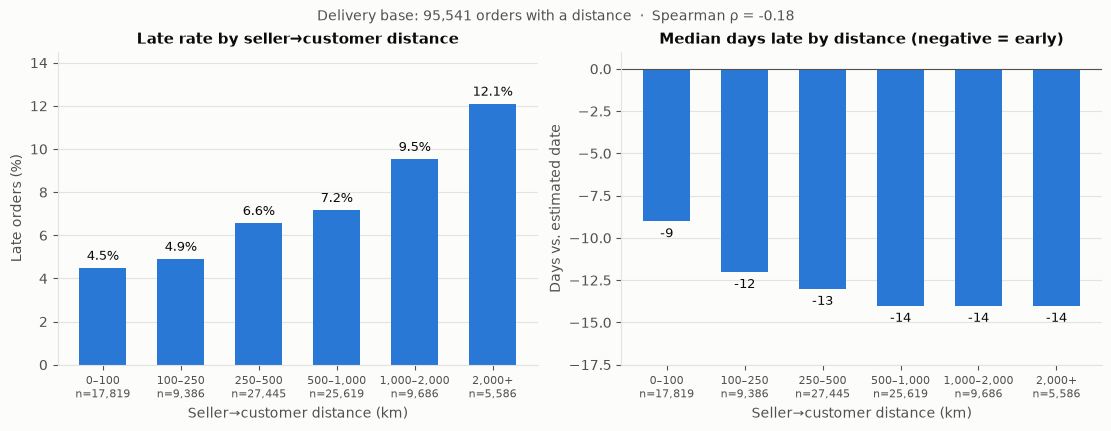

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
xt = [f"{lab}\nn={c:,}" for lab, c in zip(bands.index, bands.orders)]
x = np.arange(len(bands))

ax = axes[0]
ax.bar(x, bands.late_rate * 100, width=0.6, color=BLUE)
for xi, v in zip(x, bands.late_rate * 100):
    ax.text(xi, v + 0.25, f"{v:.1f}%", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_title("Late rate by seller→customer distance")
ax.set_ylabel("Late orders (%)")
ax.set_xticks(x, xt, fontsize=8)
ax.set_xlabel("Seller→customer distance (km)")
ax.set_ylim(0, max(bands.late_rate * 100) * 1.2)

ax = axes[1]
ax.bar(x, bands.median_days_late, width=0.6, color=BLUE)
for xi, v in zip(x, bands.median_days_late):
    ax.text(xi, v - 0.4, f"{v:.0f}", ha="center", va="top", fontsize=9, color=INK)
ax.axhline(0, color=INK2, linewidth=0.8)
ax.set_title("Median days late by distance (negative = early)")
ax.set_ylabel("Days vs. estimated date")
ax.set_xticks(x, xt, fontsize=8)
ax.set_xlabel("Seller→customer distance (km)")
ax.set_ylim(min(bands.median_days_late) * 1.25, 1)

fig.suptitle(f"Delivery base: {len(d):,} orders with a distance  ·  "
             f"Spearman ρ = {spearman.statistic:.2f}", fontsize=10, color=INK2)
fig.savefig(IMAGES / "6a_distance_vs_lateness.png", dpi=150)
plt.show()

### Testing the padding explanation

If estimates are padded more on longer trips, promised delivery time should grow with distance faster than actual delivery time. Per order: **promised days** = estimated delivery date − purchase date; **actual days** = delivered date − purchase date; **buffer** = promised − actual (= −days late). Same 95,541 orders with a distance.

In [7]:
dates = q("""
    SELECT order_id,
           DATEDIFF(day, purchase_date, estimated_delivery_date) AS promised_days,
           DATEDIFF(day, purchase_date, delivered_date)          AS actual_days
    FROM OLIST.ANALYSIS.MART_DELIVERY_ORDERS""")
d = d.drop(columns=["promised_days", "actual_days"], errors="ignore").merge(dates, on="order_id", how="left")
assert d.promised_days.notna().all() and d.actual_days.notna().all()
assert ((d.promised_days - d.actual_days) == -d.days_late).all()   # buffer = -days late

pad = (d.groupby("distance_band", observed=False)
         .agg(orders=("order_id", "size"),
              median_promised_days=("promised_days", "median"),
              median_actual_days=("actual_days", "median"),
              p90_actual_days=("actual_days", lambda s: s.quantile(0.9)),
              median_buffer_days=("days_late", lambda s: -s.median()),
              late_rate=("is_late", "mean")))
pad.style.format({"orders": "{:,}", "median_promised_days": "{:.0f}", "median_actual_days": "{:.0f}",
                  "p90_actual_days": "{:.0f}", "median_buffer_days": "{:.0f}", "late_rate": "{:.1%}"})

,orders,median_promised_days,median_actual_days,p90_actual_days,median_buffer_days,late_rate
distance_band,,,,,,
0–100,"17,819",15,5,12,9,4.5%
100–250,"9,386",20,8,16,12,4.9%
250–500,"27,445",23,10,21,13,6.6%
"500–1,000","25,619",26,12,24,14,7.2%
"1,000–2,000","9,686",30,15,30,14,9.5%
"2,000+","5,586",34,18,35,14,12.1%


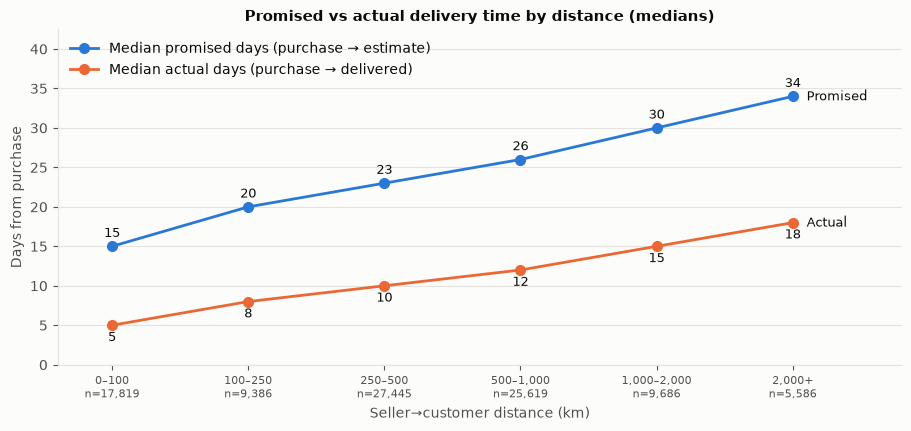

In [8]:
ORANGE = "#eb6834"
fig, ax = plt.subplots(figsize=(9, 4.2), constrained_layout=True)
x = np.arange(len(pad))
ax.plot(x, pad.median_promised_days, color=BLUE, linewidth=2, marker="o", markersize=7,
        label="Median promised days (purchase → estimate)")
ax.plot(x, pad.median_actual_days, color=ORANGE, linewidth=2, marker="o", markersize=7,
        label="Median actual days (purchase → delivered)")
for xi, (pr, ac) in enumerate(zip(pad.median_promised_days, pad.median_actual_days)):
    ax.text(xi, pr + 0.8, f"{pr:.0f}", ha="center", va="bottom", fontsize=9, color=INK)
    ax.text(xi, ac - 0.8, f"{ac:.0f}", ha="center", va="top", fontsize=9, color=INK)
ax.annotate("Promised", (x[-1], pad.median_promised_days.iloc[-1]), xytext=(10, 0),
            textcoords="offset points", va="center", fontsize=9, color=INK)
ax.annotate("Actual", (x[-1], pad.median_actual_days.iloc[-1]), xytext=(10, 0),
            textcoords="offset points", va="center", fontsize=9, color=INK)
ax.set_xticks(x, [f"{lab}\nn={c:,}" for lab, c in zip(pad.index, pad.orders)], fontsize=8)
ax.set_xlabel("Seller→customer distance (km)")
ax.set_ylabel("Days from purchase")
ax.set_title("Promised vs actual delivery time by distance (medians)")
ax.set_ylim(0, pad.median_promised_days.max() * 1.25)
ax.set_xlim(-0.4, len(pad) - 0.2)
ax.legend(frameon=False, loc="upper left")
fig.savefig(IMAGES / "6a_promised_vs_actual.png", dpi=150)
plt.show()

### Lanes ranked by number of late orders (minimum 100 orders)

Late rate shows where an order is most likely to be late; late-order count shows where fixing delivery would remove the most late orders.

In [9]:
lanes = perf[(perf.dimension == "lane") & (perf.order_count >= MIN_ORDERS)].copy()
lanes["share_of_all_late"] = lanes.late_count / late_n
by_count = (lanes.sort_values("late_count", ascending=False).head(10)
                 .rename(columns={"group_value": "lane"})
                 [["lane", "order_count", "late_count", "late_rate", "share_of_all_late", "avg_distance_km"]]
                 .reset_index(drop=True))
by_count["cumulative_share_of_late"] = by_count.share_of_all_late.cumsum()
by_count.index += 1
by_count.style.format({"order_count": "{:,}", "late_count": "{:,}", "late_rate": "{:.1%}",
                       "share_of_all_late": "{:.1%}", "cumulative_share_of_late": "{:.1%}",
                       "avg_distance_km": "{:,.0f}"})

,lane,order_count,late_count,late_rate,share_of_all_late,avg_distance_km,cumulative_share_of_late
1,SP→SP,"30,627","1,426",4.7%,21.8%,150,21.8%
2,SP→RJ,"8,124","1,152",14.2%,17.6%,441,39.5%
3,SP→MG,"7,407",393,5.3%,6.0%,495,45.5%
4,SP→BA,"2,302",297,12.9%,4.5%,"1,389",50.1%
5,SP→RS,"3,570",238,6.7%,3.6%,907,53.7%
6,SP→SC,"2,312",222,9.6%,3.4%,561,57.1%
7,SP→ES,"1,454",180,12.4%,2.8%,785,59.9%
8,SP→PR,"3,102",138,4.4%,2.1%,463,62.0%
9,SP→CE,967,133,13.8%,2.0%,"2,258",64.0%
10,PR→RJ,963,117,12.1%,1.8%,843,65.8%


## 6b. Review impact

Population: first orders with `has_full_followup` (first purchase 2017-01-01 to 2018-02-28) that are in the delivery base (so `is_late` is defined). Review comparisons also require `has_review`. Repeat purchase = `repeat_within_180d` (CLAUDE.md definitions).

**Tests.** Review score is ordinal (1–5, skewed) → Mann–Whitney U, with the mean difference and a Welch 95% CI for readability and the probability of superiority as effect size. Share of 1–2 star reviews and repeat purchase are yes/no → two-proportion z-test, Newcombe (score) 95% CI for the difference.

In [10]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
from statsmodels.stats.contingency_tables import StratifiedTable

funnel = q("""
    SELECT COUNT(*)                                             AS first_orders,
           COUNT_IF(has_full_followup)                          AS full_followup,
           COUNT_IF(has_full_followup AND is_in_delivery_base)  AS in_delivery_base,
           COUNT_IF(has_full_followup AND is_in_delivery_base AND has_review) AS with_review
    FROM OLIST.ANALYSIS.MART_REVIEW_IMPACT""")

ri = q("""
    SELECT customer_unique_id, first_purchase_month, is_late, has_review, review_score,
           repeat_within_180d
    FROM OLIST.ANALYSIS.MART_REVIEW_IMPACT
    WHERE has_full_followup AND is_in_delivery_base""")
ri["first_purchase_month"] = pd.to_datetime(ri.first_purchase_month)
assert len(ri) == funnel.in_delivery_base[0]
funnel.T.rename(columns={0: "customers"}).style.format("{:,}")

,customers
first_orders,"96,096"
full_followup,"57,184"
in_delivery_base,"55,179"
with_review,"54,770"


In [11]:
def compare_props(success, group):
    """Two-proportion comparison: late (group True) minus on-time (group False)."""
    x1, n1 = int(success[group].sum()), int(group.sum())
    x0, n0 = int(success[~group].sum()), int((~group).sum())
    z, p = proportions_ztest([x1, x0], [n1, n0])
    lo, hi = confint_proportions_2indep(x1, n1, x0, n0, method="newcomb", compare="diff")
    return {"late_n": n1, "late_rate": x1 / n1, "ontime_n": n0, "ontime_rate": x0 / n0,
            "difference": x1 / n1 - x0 / n0, "ci_low": lo, "ci_high": hi, "p_value": p}

def fmt_p(p):
    return "< 1e-300" if p == 0 else f"{p:.2e}"

rv = ri[ri.has_review]
late_s = rv.loc[rv.is_late, "review_score"].astype(float)
ontime_s = rv.loc[~rv.is_late, "review_score"].astype(float)

mw = stats.mannwhitneyu(late_s, ontime_s, alternative="two-sided")
prob_sup = mw.statistic / (len(late_s) * len(ontime_s))      # P(late > on-time) + 0.5 * P(tie)
welch = stats.ttest_ind(late_s, ontime_s, equal_var=False)
w_lo, w_hi = welch.confidence_interval(0.95)

score_tbl = pd.DataFrame([{
    "late_n": len(late_s), "late_mean": late_s.mean(),
    "ontime_n": len(ontime_s), "ontime_mean": ontime_s.mean(),
    "difference": late_s.mean() - ontime_s.mean(), "ci_low": w_lo, "ci_high": w_hi,
    "mann_whitney_p": fmt_p(mw.pvalue), "prob_superiority": prob_sup}], index=["review score (1–5)"])

low = compare_props((rv.review_score <= 2), rv.is_late)
rep = compare_props(ri.repeat_within_180d, ri.is_late)
prop_tbl = pd.DataFrame([low, rep], index=["share of 1–2 star reviews", "repeat within 180 days"])
prop_tbl["p_value"] = prop_tbl.p_value.map(fmt_p)

display(score_tbl.style.format({"late_n": "{:,}", "ontime_n": "{:,}", "late_mean": "{:.2f}",
        "ontime_mean": "{:.2f}", "difference": "{:+.2f}", "ci_low": "{:+.2f}", "ci_high": "{:+.2f}",
        "prob_superiority": "{:.3f}"}))
display(prop_tbl.style.format({"late_n": "{:,}", "ontime_n": "{:,}", "late_rate": "{:.2%}",
        "ontime_rate": "{:.2%}", "difference": "{:+.2%}", "ci_low": "{:+.2%}", "ci_high": "{:+.2%}"}))

,late_n,late_mean,ontime_n,ontime_mean,difference,ci_low,ci_high,mann_whitney_p,prob_superiority
review score (1–5),"3,577",2.18,"51,193",4.27,-2.09,-2.14,-2.04,< 1e-300,0.172


,late_n,late_rate,ontime_n,ontime_rate,difference,ci_low,ci_high,p_value
share of 1–2 star reviews,"3,577",65.39%,"51,193",9.46%,+55.93%,+54.34%,+57.50%,< 1e-300
repeat within 180 days,"3,664",2.67%,"51,515",3.20%,-0.52%,-1.02%,+0.07%,8.08e-02


Review score distribution by group (share of each group's reviews):

In [12]:
dist = (pd.crosstab(rv.review_score, rv.is_late.map({True: "late", False: "on-time"}),
                    normalize="columns")[["on-time", "late"]])
dist.style.format("{:.1%}")

is_late,on-time,late
review_score,,
1.000000,6.6%,56.6%
2.000000,2.8%,8.8%
3.000000,8.6%,10.2%
4.000000,20.9%,9.1%
5.000000,61.0%,15.3%


### Are late and on-time first orders spread similarly across purchase months?

Chi-square test of independence (month × late/on-time) with Cramér's V as effect size. Then a Cochran–Mantel–Haenszel check: the late vs on-time comparison within each month, pooled, so month mix cannot drive the result.

In [13]:
ct = pd.crosstab(ri.first_purchase_month.dt.strftime("%Y-%m"), ri.is_late)
chi2, chi_p, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f"chi-square = {chi2:,.1f}, dof = {dof}, p {'< 1e-300' if chi_p == 0 else f'= {chi_p:.2e}'}, "
      f"Cramér's V = {cramers_v:.3f}")

mix = pd.DataFrame({
    "on-time orders": ct[False], "late orders": ct[True],
    "share of on-time": ct[False] / ct[False].sum(), "share of late": ct[True] / ct[True].sum(),
    "late rate in month": ct[True] / ct.sum(axis=1)})
mix.index.name = "first purchase month"
mix.style.format({"on-time orders": "{:,}", "late orders": "{:,}", "share of on-time": "{:.1%}",
                  "share of late": "{:.1%}", "late rate in month": "{:.1%}"})

chi-square = 1,430.7, dof = 13, p = 3.80e-298, Cramér's V = 0.161


,on-time orders,late orders,share of on-time,share of late,late rate in month
first purchase month,,,,,
2017-01,694,22,1.3%,0.6%,3.1%
2017-02,"1,576",48,3.1%,1.3%,3.0%
2017-03,"2,384",116,4.6%,3.2%,4.6%
2017-04,"2,106",148,4.1%,4.0%,6.6%
2017-05,"3,342",103,6.5%,2.8%,3.0%
2017-06,"2,936",95,5.7%,2.6%,3.1%
2017-07,"3,634",102,7.1%,2.8%,2.7%
2017-08,"3,934",113,7.6%,3.1%,2.8%
2017-09,"3,825",175,7.4%,4.8%,4.4%


In [14]:
def cmh(success, group, strata):
    tables = []
    for _, g in pd.DataFrame({"y": success, "g": group, "s": strata}).groupby("s"):
        t = np.array([[((g.g) & (g.y)).sum(), ((g.g) & (~g.y)).sum()],
                      [((~g.g) & (g.y)).sum(), ((~g.g) & (~g.y)).sum()]])
        if (t.sum(axis=1) > 0).all():
            tables.append(t)
    st = StratifiedTable(tables)
    lo, hi = st.oddsratio_pooled_confint()
    return {"strata": len(tables), "pooled_odds_ratio": st.oddsratio_pooled,
            "or_ci_low": lo, "or_ci_high": hi, "cmh_p": fmt_p(st.test_null_odds().pvalue)}

month = ri.first_purchase_month.dt.strftime("%Y-%m")
cmh_tbl = pd.DataFrame([
    cmh((rv.review_score <= 2).values, rv.is_late.values, month[ri.has_review].values),
    cmh(ri.repeat_within_180d.values, ri.is_late.values, month.values)],
    index=["1–2 star share (late vs on-time)", "repeat within 180 days (late vs on-time)"])
cmh_tbl.style.format({"pooled_odds_ratio": "{:.2f}", "or_ci_low": "{:.2f}", "or_ci_high": "{:.2f}"})

,strata,pooled_odds_ratio,or_ci_low,or_ci_high,cmh_p
1–2 star share (late vs on-time),14,17.37,16.09,18.76,< 1e-300
repeat within 180 days (late vs on-time),14,0.84,0.68,1.03,9.71e-02


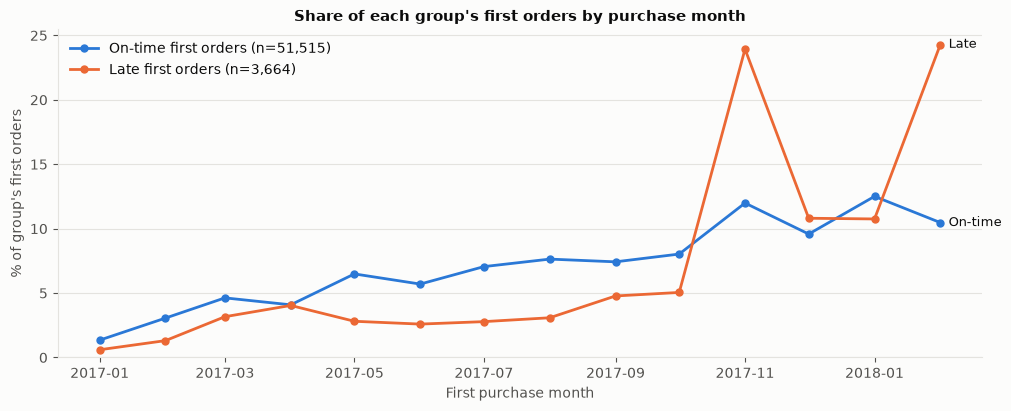

In [15]:
ORANGE = "#eb6834"
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
xm = pd.to_datetime(mix.index)
ax.plot(xm, mix["share of on-time"] * 100, color=BLUE, linewidth=2, marker="o", markersize=5,
        label=f"On-time first orders (n={ct[False].sum():,})")
ax.plot(xm, mix["share of late"] * 100, color=ORANGE, linewidth=2, marker="o", markersize=5,
        label=f"Late first orders (n={ct[True].sum():,})")
for col, colr, name in [("share of on-time", BLUE, "On-time"), ("share of late", ORANGE, "Late")]:
    ax.annotate(name, (xm[-1], mix[col].iloc[-1] * 100), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK)
ax.set_title("Share of each group's first orders by purchase month")
ax.set_ylabel("% of group's first orders")
ax.set_xlabel("First purchase month")
ax.legend(frameon=False, loc="upper left")
ax.set_ylim(0, None)
fig.savefig(IMAGES / "6b_month_mix.png", dpi=150)
plt.show()

In [16]:
try:
    conn.cursor().execute("ALTER WAREHOUSE OLIST_WH SUSPEND")  # stop credits now
except snowflake.connector.errors.ProgrammingError:
    pass  # already auto-suspended
conn.close()